## Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Load data:

df = pd.read_csv(f"data/amz_uk_price_prediction_dataset.csv")

## Exploring the data

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [6]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.value_counts("stars")

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [9]:
df.value_counts("reviews")

reviews
0         1225641
1           90033
2           54452
3           39922
4           30720
           ...   
479359          1
369943          1
474942          1
238541          1
289577          1
Name: count, Length: 19446, dtype: int64

## Part 1: Analyzing Best-Seller Trends Across Product Categories

In [10]:
#normalize by rows to compare categories between each other whitout the sizes of those affect the reading.

cat_vs_bs = pd.crosstab(df['category'], df['isBestSeller'], normalize= 'index')
cat_vs_bs

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [11]:
#organize in descending way

cat_vs_bs.sort_values(by=True, ascending=False)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
Bedding Collections,1.000000,0.000000
CPUs,1.000000,0.000000
"CD, Disc & Tape Players",1.000000,0.000000


In [12]:
from scipy.stats import chi2_contingency

# usa la tabla SIN normalize, la de conteos
tabla_conteos = pd.crosstab(df['category'], df['isBestSeller'])

chi2, p, dof, expected = chi2_contingency(tabla_conteos)

In [13]:
n = tabla_conteos.sum().sum()
r, k = tabla_conteos.shape
cramers_v = (chi2 / (n * (min(r, k) - 1))) ** 0.5

In [14]:
print(f"Chi2: {chi2}")
print(f"p-value: {p}")
print(f"Cramér's V: {cramers_v}")

Chi2: 36540.20270061387
p-value: 0.0
Cramér's V: 0.1222829439760564


La categoría de producto sí está asociada con la probabilidad de ser best-seller (estadísticamente confirmado), pero la fuerza de esa asociación es modesta — la categoría por sí sola no es un predictor fuerte de si un producto será best-seller. Hay otros factores (precio, reviews, marca...) que probablemente pesan más.

Esto es un matiz importante para tu reporte: "significativo" ≠ "fuerte", y con datasets grandes siempre hay que reportar ambos (p-value y el tamaño del efecto) para no exagerar la importancia de una relación débil.

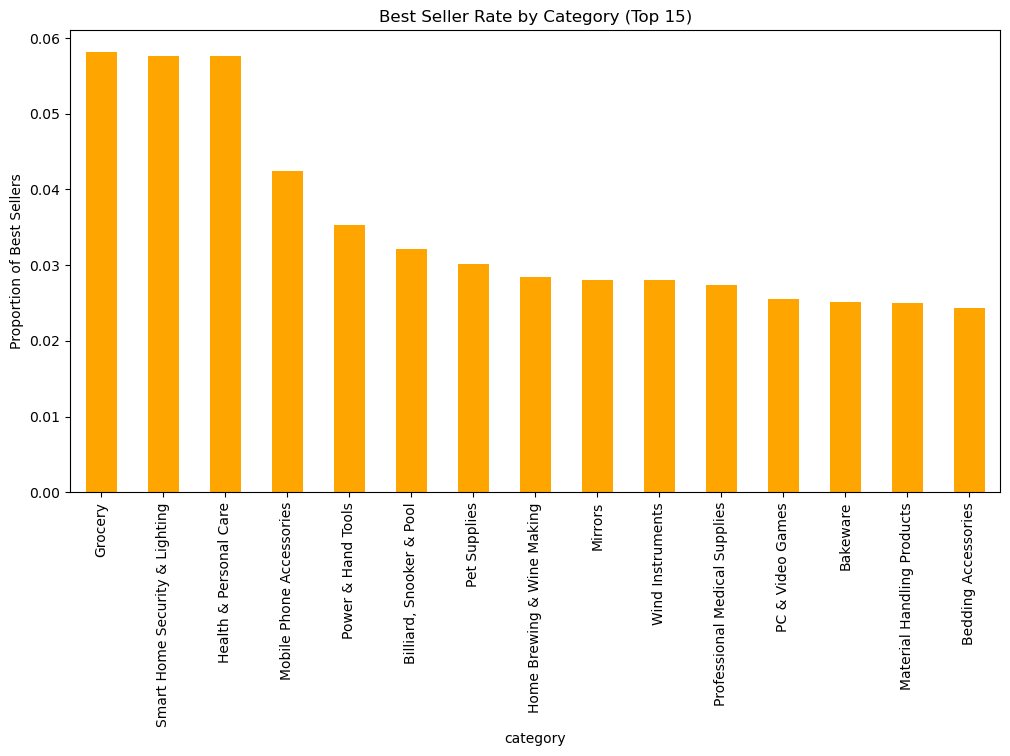

In [15]:
cat_vs_bs[True].sort_values(ascending=False).head(15).plot(kind='bar', figsize=(12,6), color='orange')
plt.title('Best Seller Rate by Category (Top 15)')
plt.ylabel('Proportion of Best Sellers')
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [16]:
# --- Step 0: Remove outliers in product prices using the IQR method ---

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"\nOriginal shape: {df.shape}")
print(f"Shape without outliers: {df_no_outliers.shape}")
print(f"Rows removed: {df.shape[0] - df_no_outliers.shape[0]}")

Q1: 9.99
Q3: 45.99
IQR: 36.0
Lower bound: -44.01
Upper bound: 99.99000000000001

Original shape: (2443651, 9)
Shape without outliers: (2115963, 9)
Rows removed: 327688


### Part 2.1: Violin Plots — Price distribution across categories

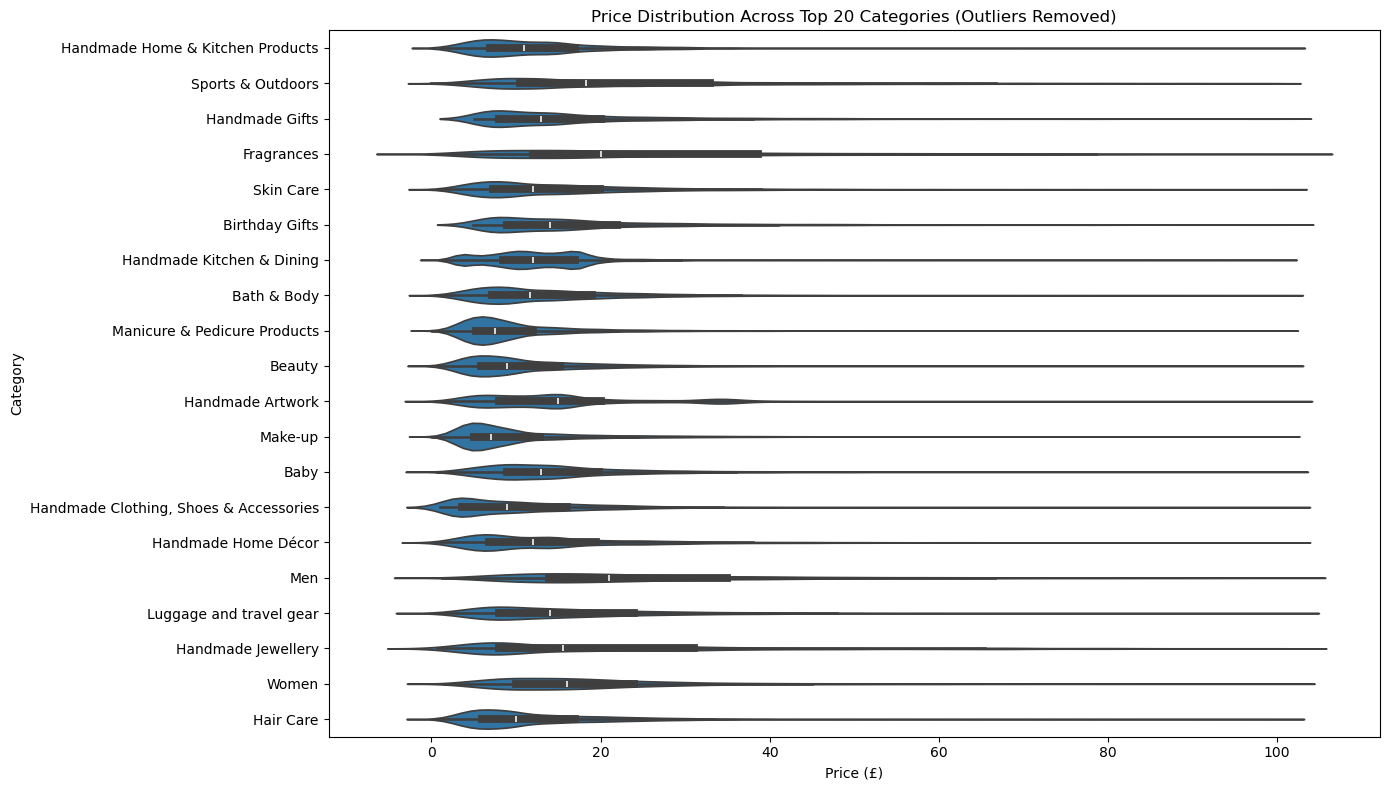

In [17]:
top20_categories = df_no_outliers['category'].value_counts().head(20).index
subset_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

plt.figure(figsize=(14, 8))
sns.violinplot(data=subset_top20, x='price', y='category', orient='h')
plt.title('Price Distribution Across Top 20 Categories (Outliers Removed)')
plt.xlabel('Price (£)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

In [18]:
# Which category has the highest median price? (ALL categories, not just top 20)
median_price_by_category = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
print("Category with highest median price:")
print(median_price_by_category.head(1))

Category with highest median price:
category
Desktop PCs    74.0
Name: price, dtype: float64


### Part 2.2: Bar Chart — Average price for top 10 categories (by count)

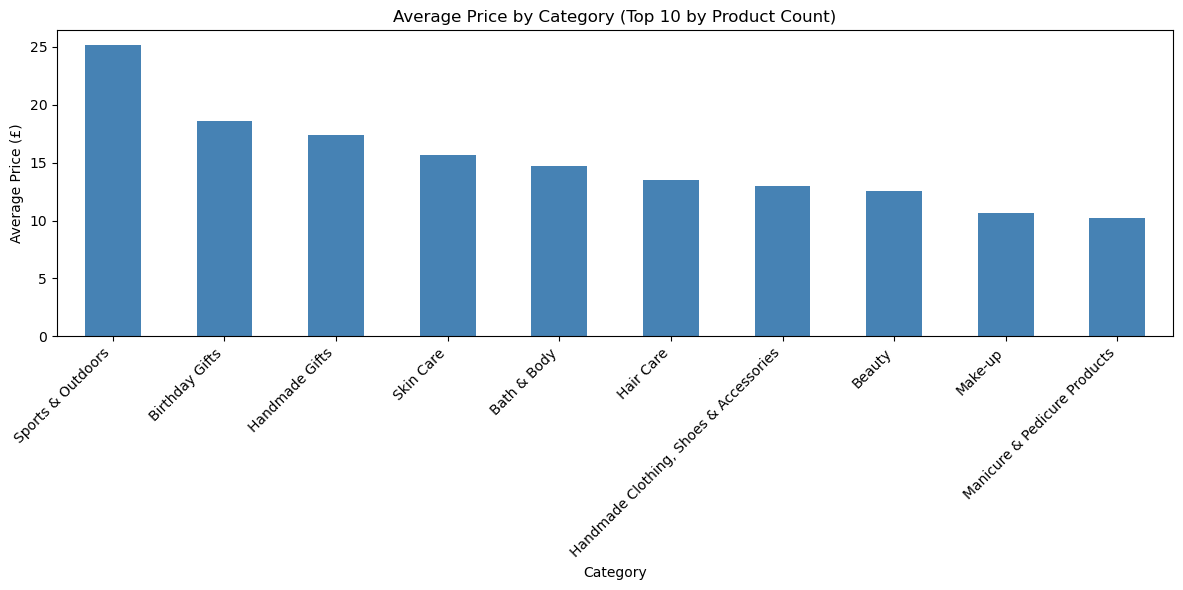

In [19]:
top10_categories = df_no_outliers['category'].value_counts().head(10).index
subset_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

avg_price_top10 = subset_top10.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_price_top10.plot(kind='bar', color='steelblue')
plt.title('Average Price by Category (Top 10 by Product Count)')
plt.xlabel('Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [20]:
# Which category commands the highest average price? (ALL categories, not just top 10)
avg_price_by_category = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
print("Category with highest average price:")
print(avg_price_by_category.head(1))

Category with highest average price:
category
Motherboards    68.772432
Name: price, dtype: float64


### Part 2.3: Box Plots — Rating distribution across categories

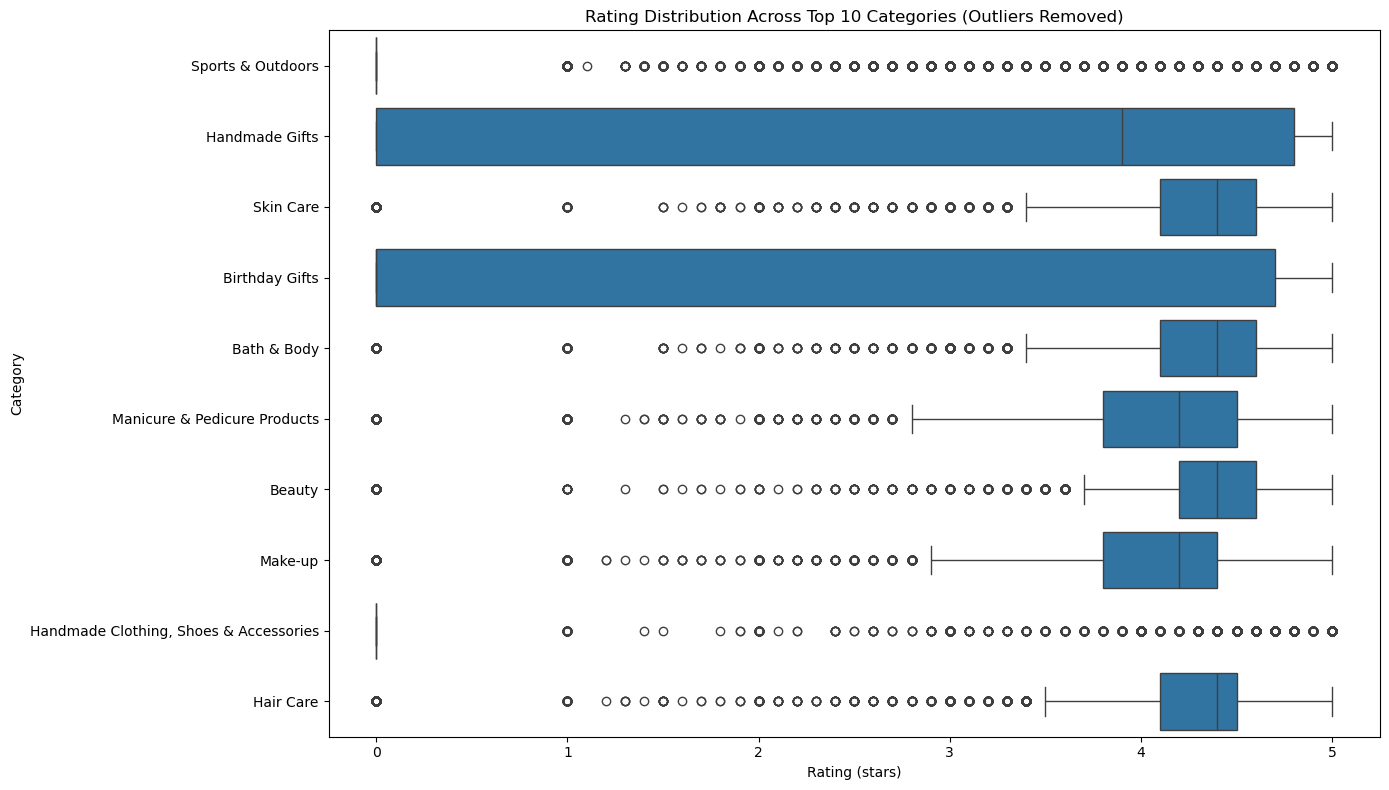

In [21]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=subset_top10, x='stars', y='category', orient='h')
plt.title('Rating Distribution Across Top 10 Categories (Outliers Removed)')
plt.xlabel('Rating (stars)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

In [22]:
# Which category has the highest median rating? (ALL categories, not just top 10)
median_rating_by_category = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
print("Category with highest median rating:")
print(median_rating_by_category.head(1))

Category with highest median rating:
category
Computer Memory    4.7
Name: stars, dtype: float64


## Part 3: Investigating the Interplay Between Product Prices and Ratings

### Part 3.1: Correlation coefficient between price and stars

In [23]:
# Note: excluding stars == 0, since these represent products with no reviews yet,
# not products that genuinely received a 0-star rating (mixing both would distort the correlation)
df_rated = df_no_outliers[df_no_outliers['stars'] > 0]

correlation = df_rated['price'].corr(df_rated['stars'])
print(f"Correlation coefficient between price and stars: {correlation:.4f}")

Correlation coefficient between price and stars: 0.0067


### Part 3.2: Scatter plot — price vs rating

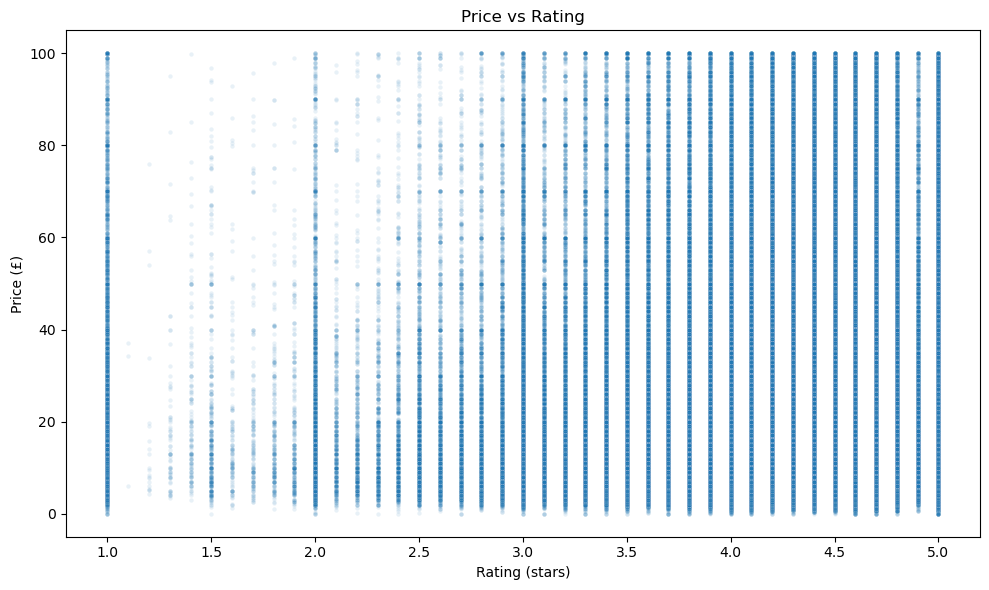

In [24]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_rated, x='stars', y='price', alpha=0.1, s=10)
plt.title('Price vs Rating')
plt.xlabel('Rating (stars)')
plt.ylabel('Price (£)')
plt.tight_layout()
plt.show()

### Part 3.3: Correlation heatmap — all numerical variables

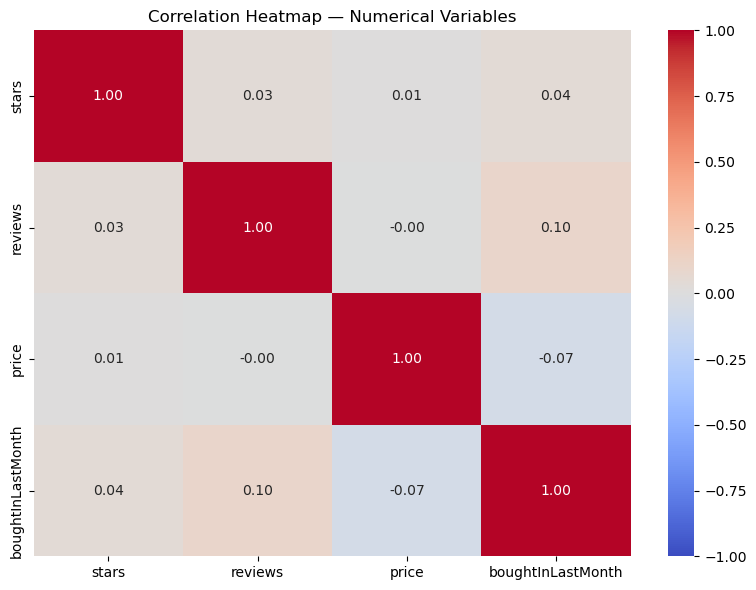

In [25]:
numerical_cols = ['stars', 'reviews', 'price', 'boughtInLastMonth']
corr_matrix = df_rated[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation Heatmap — Numerical Variables')
plt.tight_layout()
plt.show()

### Part 3.4: QQ Plot — checking if price follows a normal distribution

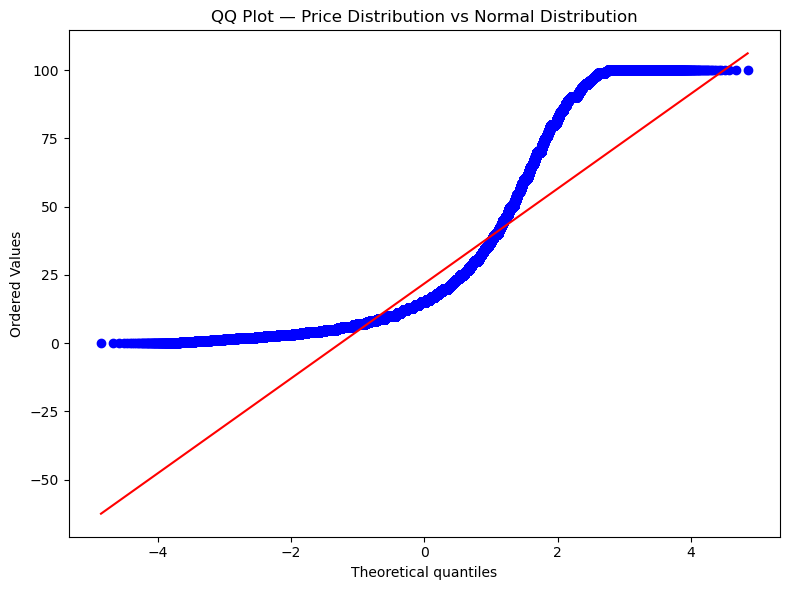

In [26]:
import scipy.stats as stats

plt.figure(figsize=(8, 6))
stats.probplot(df_rated['price'], dist="norm", plot=plt)
plt.title('QQ Plot — Price Distribution vs Normal Distribution')
plt.tight_layout()
plt.show()

## Bonus: Repeating the analysis without removing outliers

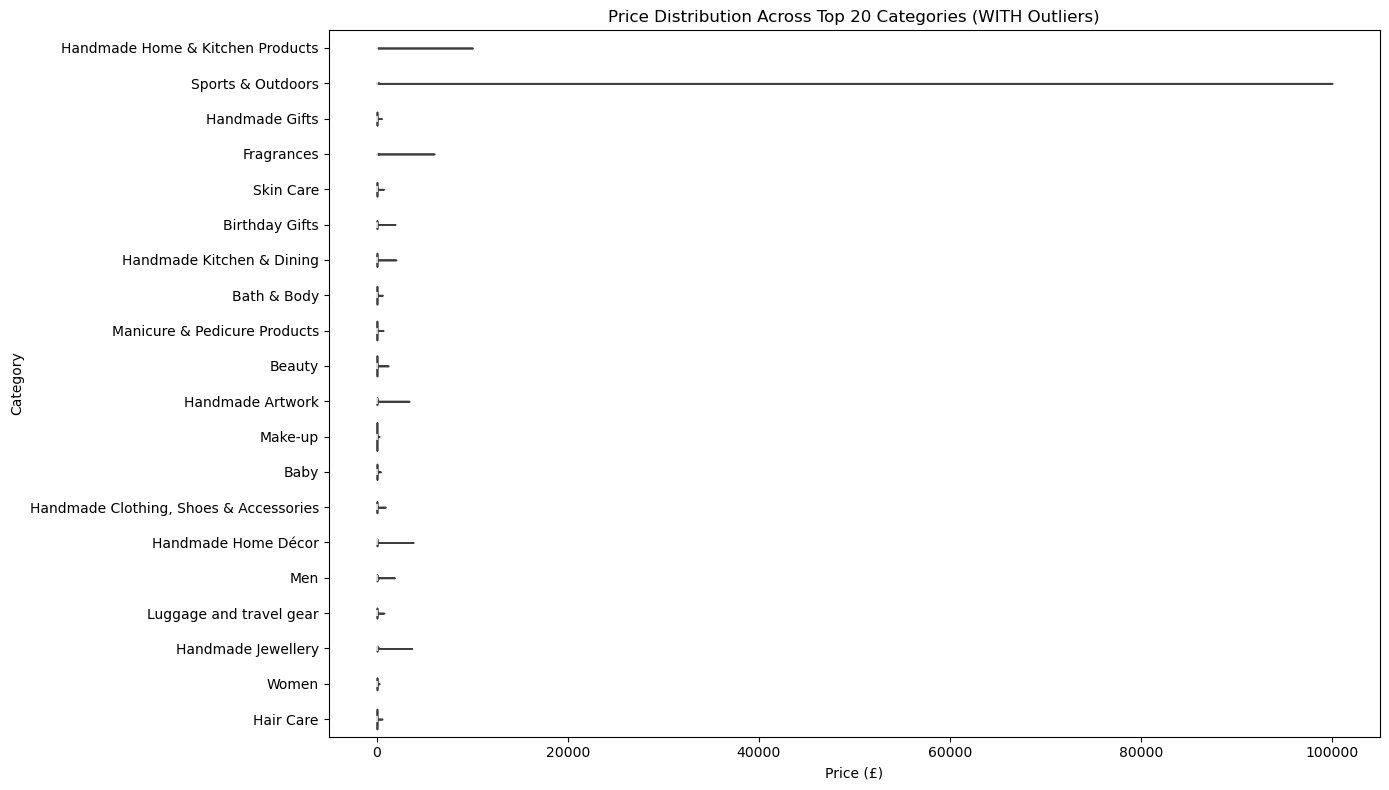

In [27]:
# --- Violin plot: price distribution across top 20 categories (WITH outliers) ---

subset_top20_full = df[df['category'].isin(top20_categories)]

plt.figure(figsize=(14, 8))
sns.violinplot(data=subset_top20_full, x='price', y='category', orient='h')
plt.title('Price Distribution Across Top 20 Categories (WITH Outliers)')
plt.xlabel('Price (£)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

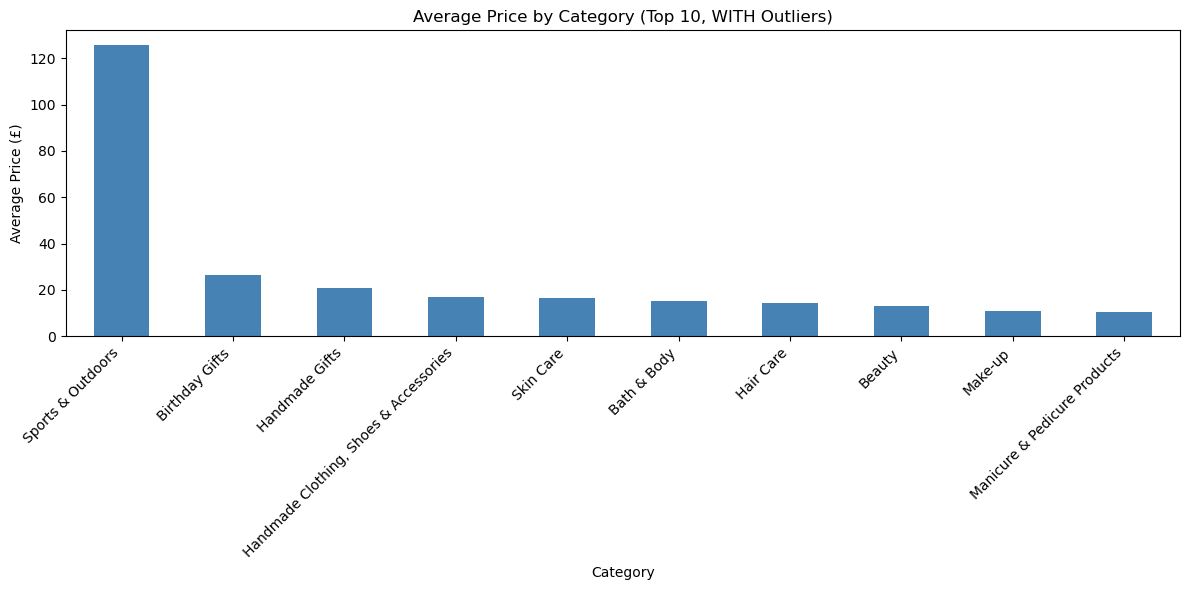

In [28]:
# --- Bar chart: average price for top 10 categories (WITH outliers) ---

subset_top10_full = df[df['category'].isin(top10_categories)]
avg_price_top10_full = subset_top10_full.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_price_top10_full.plot(kind='bar', color='steelblue')
plt.title('Average Price by Category (Top 10, WITH Outliers)')
plt.xlabel('Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [29]:
# --- Correlation coefficient: price vs stars (WITH outliers, still excluding stars==0) ---

df_rated_full = df[df['stars'] > 0]
correlation_full = df_rated_full['price'].corr(df_rated_full['stars'])
print(f"Correlation coefficient (with outliers): {correlation_full:.4f}")
print(f"Correlation coefficient (without outliers): {correlation:.4f}")

Correlation coefficient (with outliers): -0.0049
Correlation coefficient (without outliers): 0.0067


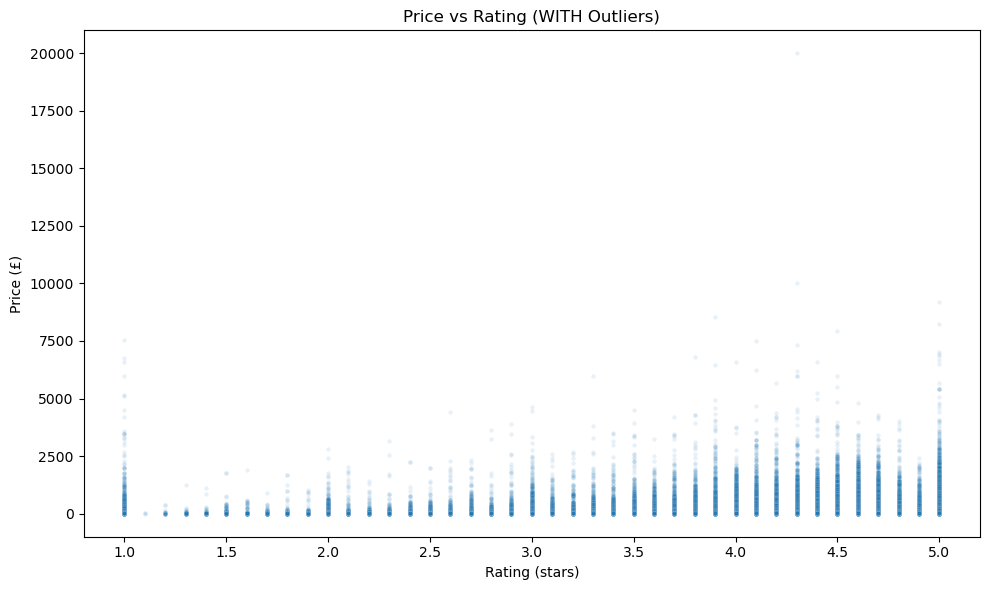

In [30]:
# --- Scatter plot: price vs rating (WITH outliers) ---

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_rated_full, x='stars', y='price', alpha=0.1, s=10)
plt.title('Price vs Rating (WITH Outliers)')
plt.xlabel('Rating (stars)')
plt.ylabel('Price (£)')
plt.tight_layout()
plt.show()

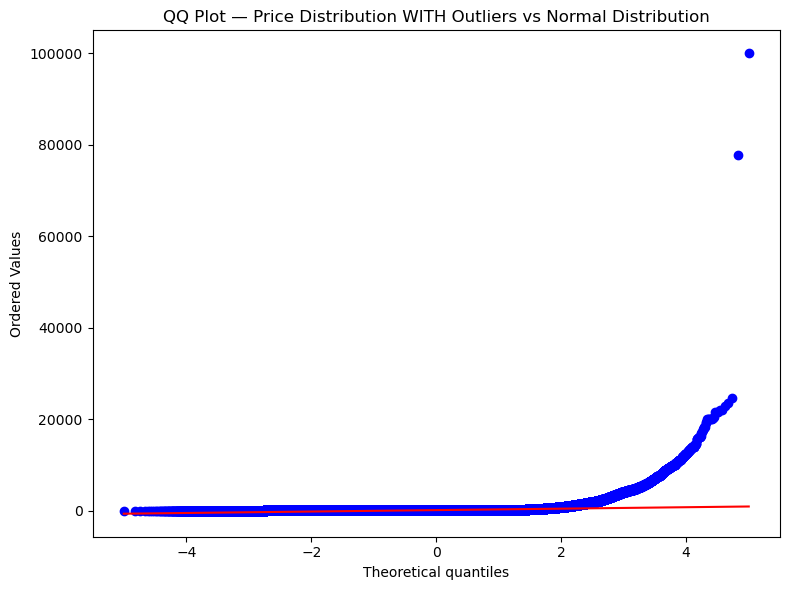

In [31]:
# --- QQ Plot: price distribution (WITH outliers) ---

plt.figure(figsize=(8, 6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title('QQ Plot — Price Distribution WITH Outliers vs Normal Distribution')
plt.tight_layout()
plt.show()

### Bonus insights

- **Violin plots**: with outliers, the tails stretch dramatically for categories that contain a few very expensive products (e.g. high-end electronics), making the bulk of the distribution visually harder to read — the IQR-cleaned version is much more interpretable for comparing typical prices across categories.
- **Average price**: category rankings by mean price can shift noticeably with outliers included, since a handful of very expensive products can pull a category's average far above its typical (median) price.
- **Correlation & scatter**: outliers can inflate or deflate the price-rating correlation depending on where those extreme-priced products cluster on the ratings axis — worth checking if the correlation coefficient changes meaningfully between the two versions.
- **QQ plot**: with outliers, the deviation from normality in the upper tail becomes even more pronounced, reinforcing that `price` is heavily right-skewed regardless of outlier treatment.

## Summary of Findings — Business Report

### Part 1: Category vs Best-Seller Status
Product category shows a **statistically significant** association with best-seller status (χ² test, p ≈ 0), but the strength of that association is **modest** (Cramér's V = 0.122). Categories like **Grocery**, **Smart Home Security & Lighting**, and **Health & Personal Care** have the highest best-seller rates (~5.8%), while most categories cluster in the 1–3% range. This suggests best-seller status is driven more by category-specific dynamics (repeat purchases, customer trust, competition) than by category alone.

### Part 2: Prices and Ratings Across Categories
- **Highest median price**: **Desktop PCs** (£74.0) — consistent with expectations, as PCs are complex, higher-value items compared to most Amazon UK product categories.
- **Highest average price**: **Motherboards** (£68.77) — a related tech category, reinforcing that computing components command the highest price points on the platform.
- **Highest median rating**: **Computer Memory** (4.7 stars) — note that this metric can be sensitive to categories with fewer products and to the large share of unrated (`stars = 0`) products in the dataset; results should be read with that caveat in mind.

### Part 3: Price vs Rating Relationship
- **Correlation coefficient (price vs stars, outliers removed, unrated products excluded)**: **0.0067** — essentially **no linear relationship**. Customers do not rate expensive products systematically higher or lower than cheaper ones.
- The **scatter plot** and **correlation heatmap** confirm this: `price` shows negligible correlation with `stars`, `reviews`, or `boughtInLastMonth`.
- The **QQ plot** shows `price` clearly **deviates from a normal distribution**, especially in the upper tail — consistent with the right-skewed shape already suggested by the earlier `describe()` output (mean >> median).

### Bonus: Effect of Outlier Removal
- Removing outliers barely changed the price–rating correlation (**-0.0049 with outliers** vs **0.0067 without**) — both are effectively zero, so outlier treatment does not materially affect this particular conclusion.
- However, outlier removal **does matter** for the violin plots and average-price bar charts, where a handful of extremely expensive products can distort visual comparisons and inflate category averages. For distributional analysis and visualization, the outlier-free dataset gives a more representative picture of typical pricing.

### Key Business Takeaway
Price and category are **not reliable predictors of customer satisfaction** (rating) or best-seller status on Amazon UK. Best-seller status correlates more with category-level purchase dynamics (recurrence, trust) than price positioning, and pricing strategy should be informed primarily by category norms (e.g. computing components support higher price points) rather than an assumption that higher prices signal or require higher perceived quality.